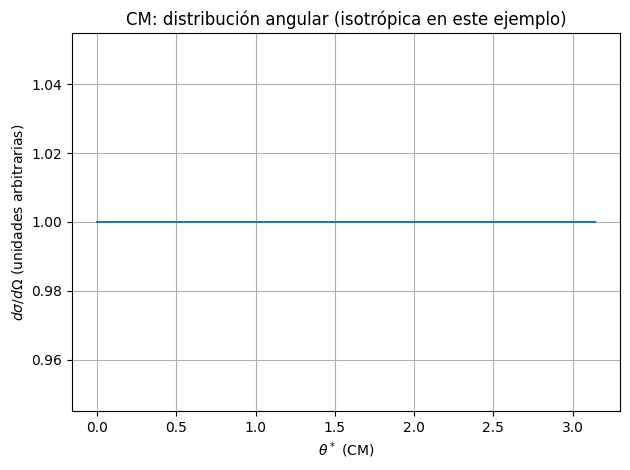

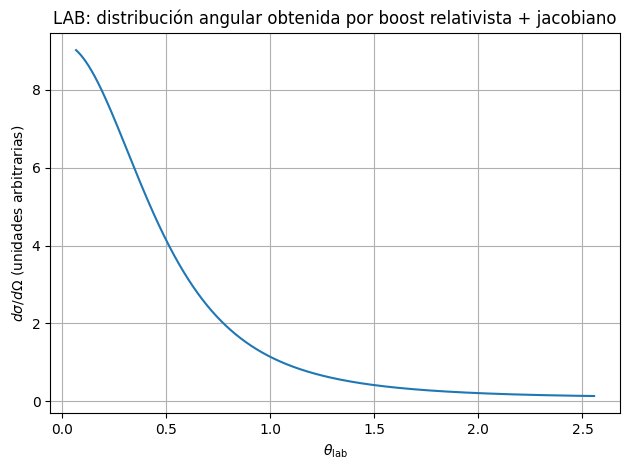

Parámetros:
beta = 0.8 gamma = 1.666666666666667 v* = 0.98
Ejemplo (normalización CM = 1):
dσ/dΩ_lab(theta_lab~0)   = 9.021133786848075
dσ/dΩ_lab(theta_lab~pi/2)= 0.3672881538598136


In [1]:
import numpy as np
import matplotlib.pyplot as plt

# -----------------------------
# Parámetros (elige tú)
# -----------------------------
beta = 0.8                      # velocidad del CM respecto al LAB (0<beta<1)
gamma = 1.0 / np.sqrt(1.0 - beta**2)

v_star = 0.98                   # v* = p*/E* de la partícula final en el CM (0<v*<=1)
dsdo_cm_const = 1.0             # distribución isotrópica en CM (normalización arbitraria)

N = 5000                        # puntos para muestrear cos(theta*)

# -----------------------------
# 1) Malla en CM
# -----------------------------
cos_star = np.linspace(-1.0, 1.0, N)
theta_star = np.arccos(cos_star)

# -----------------------------
# 2) Relación angular (aberración) CM -> LAB
#    cos(theta_lab) = (beta + v* cos(theta*))/(1 + beta v* cos(theta*))
# -----------------------------
cos_lab = (beta + v_star * cos_star) / (1.0 + beta * v_star * cos_star)
cos_lab = np.clip(cos_lab, -1.0, 1.0)
theta_lab = np.arccos(cos_lab)

# -----------------------------
# 3) Jacobiano |d cos(theta*) / d cos(theta_lab)|
#    = gamma^2 (1 + beta v* cos(theta*))^2 / v*
# -----------------------------
jac = gamma**2 * (1.0 + beta * v_star * cos_star)**2 / v_star

# Distribución en LAB desde invariancia dσ = (dσ/dΩ) dΩ
dsdo_lab = dsdo_cm_const * jac

# Para graficar suave en función de theta_lab, ordenamos por theta_lab
idx = np.argsort(theta_lab)
theta_lab_sorted = theta_lab[idx]
dsdo_lab_sorted = dsdo_lab[idx]

# -----------------------------
# 4) Gráficas
# -----------------------------
plt.figure()
plt.plot(theta_star, dsdo_cm_const * np.ones_like(theta_star))
plt.xlabel(r'$\theta^*$ (CM)')
plt.ylabel(r'$d\sigma/d\Omega$ (unidades arbitrarias)')
plt.title('CM: distribución angular (isotrópica en este ejemplo)')
plt.grid(True)
plt.tight_layout()
plt.show()

plt.figure()
plt.plot(theta_lab_sorted, dsdo_lab_sorted)
plt.xlabel(r'$\theta_{\mathrm{lab}}$')
plt.ylabel(r'$d\sigma/d\Omega$ (unidades arbitrarias)')
plt.title('LAB: distribución angular obtenida por boost relativista + jacobiano')
plt.grid(True)
plt.tight_layout()
plt.show()

# -----------------------------
# 5) Números de referencia
# -----------------------------
i0 = np.argmin(np.abs(theta_lab_sorted - 0.0))
i90 = np.argmin(np.abs(theta_lab_sorted - np.pi/2))
print("Parámetros:")
print("beta =", beta, "gamma =", gamma, "v* =", v_star)
print("Ejemplo (normalización CM = 1):")
print("dσ/dΩ_lab(theta_lab~0)   =", dsdo_lab_sorted[i0])
print("dσ/dΩ_lab(theta_lab~pi/2)=", dsdo_lab_sorted[i90])

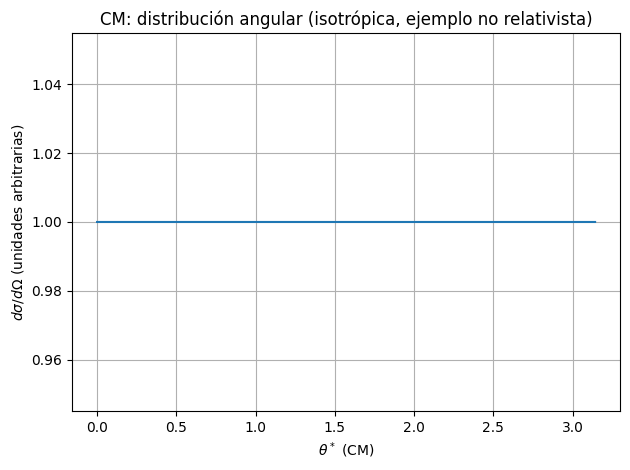

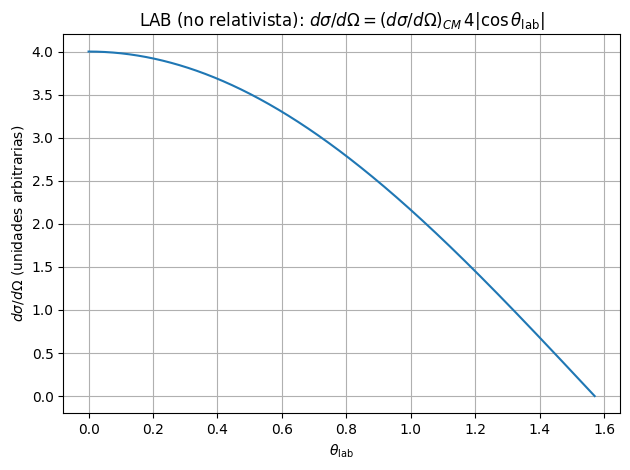

Chequeo rápido:
dσ/dΩ_lab(theta_lab=0)   = 4.0
dσ/dΩ_lab(theta_lab=pi/2)= 2.4492935982947064e-16


In [2]:
import numpy as np
import matplotlib.pyplot as plt

# -----------------------------
# Distribución en CM (elige modelo)
# Aquí isotrópica como ejemplo:
# -----------------------------
dsdo_cm_const = 1.0

# Malla en theta_lab
N = 2000
theta_lab = np.linspace(0.0, np.pi/2, N)  # para masas iguales en blanco fijo, theta_lab <= pi/2
cos_lab = np.cos(theta_lab)

# Relación angular no relativista: theta* = 2 theta_lab
theta_star = 2.0 * theta_lab
cos_star = np.cos(theta_star)

# Jacobiano no relativista: |d cos* / d cos_lab| = 4 |cos(theta_lab)|
jac_nr = 4.0 * np.abs(cos_lab)

# Distribución en LAB
dsdo_lab = dsdo_cm_const * jac_nr

# -----------------------------
# Gráficas
# -----------------------------
plt.figure()
plt.plot(theta_star, dsdo_cm_const * np.ones_like(theta_star))
plt.xlabel(r'$\theta^*$ (CM)')
plt.ylabel(r'$d\sigma/d\Omega$ (unidades arbitrarias)')
plt.title('CM: distribución angular (isotrópica, ejemplo no relativista)')
plt.grid(True)
plt.tight_layout()
plt.show()

plt.figure()
plt.plot(theta_lab, dsdo_lab)
plt.xlabel(r'$\theta_{\mathrm{lab}}$')
plt.ylabel(r'$d\sigma/d\Omega$ (unidades arbitrarias)')
plt.title(r'LAB (no relativista): $d\sigma/d\Omega = (d\sigma/d\Omega)_{CM}\,4|\cos\theta_{\rm lab}|$')
plt.grid(True)
plt.tight_layout()
plt.show()

print("Chequeo rápido:")
print("dσ/dΩ_lab(theta_lab=0)   =", dsdo_lab[0])
print("dσ/dΩ_lab(theta_lab=pi/2)=", dsdo_lab[-1])